# Paper 28: Generative Adversarial Networks & WGAN-GP
**Authors**: Ian J. Goodfellow et al. (NeurIPS 2014) & Ishaan Gulrajani et al. (NeurIPS 2017)

---

## 1. The Core Breakdown: Jensen-Shannon Divergence & Vanishing Gradients
In classic GANs (Goodfellow 2014), the minimax game minimizes the Jensen-Shannon (JS) divergence:
$$\min_G \max_D \mathbb{E}_{x \sim p_{\text{data}}}[\log D(x)] + \mathbb{E}_{z \sim p_z}[\log(1 - D(G(z)))]$$
In high-dimensional spaces, real and generated manifolds almost never intersect. When supports are disjoint:
$$D_{\text{JS}}(p_{\text{data}} \parallel p_g) = \log 2 = \text{constant} \implies \nabla_{\theta_G} D_{\text{JS}} = 0$$
The discriminator saturates with 100% accuracy, causing **vanishing gradients** and **catastrophic mode collapse**.

## 2. Earth Mover's (Wasserstein-1) Distance
Wasserstein distance measures the minimum cost of transporting mass from distribution $p_r$ to $p_g$. By Kantorovich-Rubinstein duality:
$$W_1(p_r, p_g) = \sup_{\|D\|_L \le 1} \mathbb{E}_{x \sim p_r}[D(x)] - \mathbb{E}_{\tilde{x} \sim p_g}[D(\tilde{x})]$$
where $D$ is a **Critic** constrained to be **1-Lipschitz continuous**.

## 3. The Gradient Penalty (WGAN-GP)
Gulrajani et al. enforce the 1-Lipschitz condition directly on random interpolates $\hat{x} = \epsilon x + (1 - \epsilon)\tilde{x}$:
$$\mathcal{L}_{\text{critic}} = \mathbb{E}[D(\tilde{x})] - \mathbb{E}[D(x)] + \lambda \cdot \mathbb{E}_{\hat{x}}\left[(\|\nabla_{\hat{x}} D(\hat{x})\|_2 - 1)^2\right]$$
$$\mathcal{L}_{\text{gen}} = -\mathbb{E}_{z}[D(G(z))]$$

---
## Setup & Autoreload

In [1]:
%load_ext autoreload
%autoreload 2

import math
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

# Set seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


---
## Unit Tests Execution
Run the full verification suite against reference solution and student template.

In [2]:
import sys
import importlib
from pathlib import Path

# Add repository root to pythonpath
repo_root = Path("../..").resolve()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

# Local tests and student template
import tests
import model as student_model

# Reference solution (dynamically imported since folder name starts with digits)
solution_model = importlib.import_module("solutions.28_gan.model")

print("Testing Reference Solution:")
tests.test_shapes_and_contracts(solution_model)
tests.test_gradient_penalty_math(solution_model)
tests.test_loss_contracts(solution_model)
tests.test_adversarial_overfitting_gate(solution_model)
print("\nAll tests verified successfully on solution!")

print("\nTesting Student Template (model.py):")
try:
    tests.test_shapes_and_contracts(student_model)
    print("Student tests passed!")
except NotImplementedError as e:
    print(f"Student implementation pending: {e}")

Testing Reference Solution:
Running Test 1: Generator/Critic Tensor Shape Contracts... [PASS]
Running Test 2: Gradient Penalty Math & 1-Lipschitz Audit... [PASS]
Running Test 3: WGAN-GP Loss Mathematical Contracts... [PASS]
Running Test 4: Adversarial Overfitting Gate... [PASS] (Critic stable, final std=0.709)

All tests verified successfully on solution!

Testing Student Template (model.py):
Running Test 1: Generator/Critic Tensor Shape Contracts... [PASS]
Student tests passed!


---
## Interactive Experiment: Training WGAN-GP on Geometric Patterns
We train WGAN-GP on 8 geometric patterns (stripes, boxes, gradients) scaled to $[-1, 1]$.

Training WGAN-GP...
Epoch   1 | W-Dist Estimate: 3.1698 | GP: 0.1099 | G-Loss: 3.6497
Epoch  30 | W-Dist Estimate: 9.7653 | GP: 0.0783 | G-Loss: 8.6520
Epoch  60 | W-Dist Estimate: 13.0110 | GP: 0.1249 | G-Loss: 9.0268
Epoch  90 | W-Dist Estimate: 10.5717 | GP: 0.0410 | G-Loss: 10.4606
Epoch 120 | W-Dist Estimate: 13.9721 | GP: 0.5426 | G-Loss: 12.1023


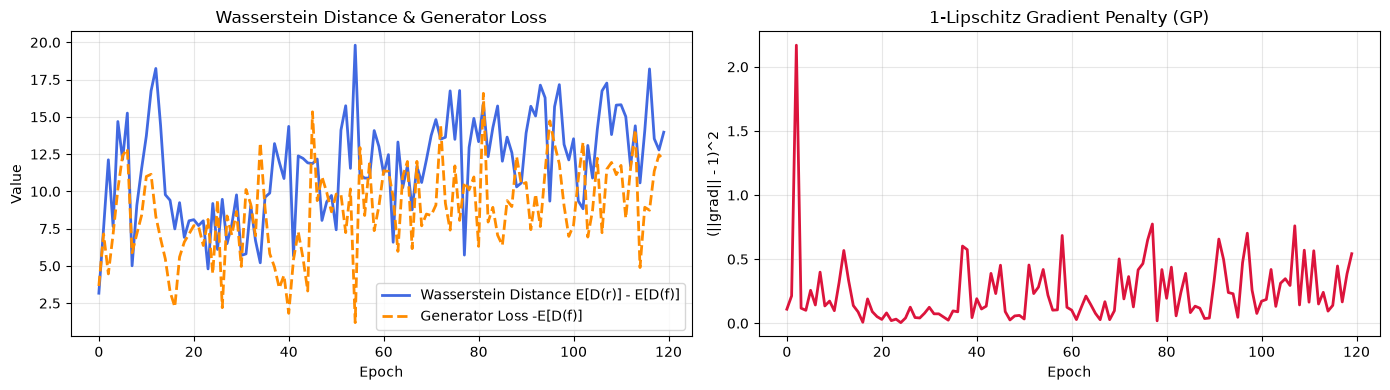

In [3]:
import importlib
solution_model = importlib.import_module("solutions.28_gan.model")
WGANGP = solution_model.WGANGP
critic_loss = solution_model.critic_loss
generator_loss = solution_model.generator_loss

# Create 8 distinct 28x28 geometric training patterns in [-1, 1]
x_train = torch.full((8, 1, 28, 28), -1.0, device=device)
x_train[0, 0, :, 12:16] = 1.0           # Vertical stripe
x_train[1, 0, 12:16, :] = 1.0           # Horizontal stripe
x_train[2, 0, 8:20, 8:20] = 1.0         # Center square
x_train[3, 0, :, :] = 0.0               # Neutral gray
x_train[4, 0, :14, :14] = 1.0           # Top-left quad
x_train[5, 0, 14:, 14:] = 1.0           # Bottom-right quad
x_train[6, 0] = torch.linspace(-1, 1, 28).unsqueeze(0).repeat(28, 1)  # Gradient H
x_train[7, 0] = torch.linspace(-1, 1, 28).unsqueeze(1).repeat(1, 28)  # Gradient V

# Initialize WGAN-GP
wgan = WGANGP(
    latent_dim=32,
    img_channels=1,
    hidden_dim=32,
    img_size=28,
    lambda_gp=10.0,
).to(device)

opt_c = optim.Adam(wgan.critic.parameters(), lr=1e-3, betas=(0.0, 0.9))
opt_g = optim.Adam(wgan.generator.parameters(), lr=1e-3, betas=(0.0, 0.9))

history = {"w_dist": [], "gp": [], "g_loss": []}
B = 8

print("Training WGAN-GP...")
for epoch in range(1, 121):
    # 1. Update Critic (2 critic steps per generator step)
    for _ in range(2):
        opt_c.zero_grad()
        z = torch.randn(B, 32, device=device)
        with torch.no_grad():
            fake = wgan.generate(z)
        c_loss, w_loss, gp = critic_loss(wgan.critic, x_train, fake, lambda_gp=10.0)
        c_loss.backward()
        opt_c.step()

    # 2. Update Generator
    opt_g.zero_grad()
    z = torch.randn(B, 32, device=device)
    fake = wgan.generate(z)
    g_loss = generator_loss(wgan.critic, fake)
    g_loss.backward()
    opt_g.step()

    w_dist = -w_loss.item()  # E[D(real)] - E[D(fake)]
    history["w_dist"].append(w_dist)
    history["gp"].append(gp.item())
    history["g_loss"].append(g_loss.item())

    if epoch % 30 == 0 or epoch == 1:
        print(f"Epoch {epoch:3d} | W-Dist Estimate: {w_dist:.4f} | GP: {gp.item():.4f} | G-Loss: {g_loss.item():.4f}")

# Plot training trajectories
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.plot(history["w_dist"], label="Wasserstein Distance E[D(r)] - E[D(f)]", color="royalblue", lw=2)
ax1.plot(history["g_loss"], label="Generator Loss -E[D(f)]", color="darkorange", lw=2, linestyle="--")
ax1.set_title("Wasserstein Distance & Generator Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Value")
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.plot(history["gp"], color="crimson", lw=2)
ax2.set_title("1-Lipschitz Gradient Penalty (GP)")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("(||grad|| - 1)^2")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## Generated Samples from Latent Prior $z \sim \mathcal{N}(0, I)$

<>:13: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:13: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
C:\Users\hp\AppData\Local\Temp\ipykernel_16968\4245317643.py:13: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  plt.suptitle("Generated Visual Patterns Sampled from Noise Prior $z \sim \mathcal{N}(0, I)$", fontsize=14)


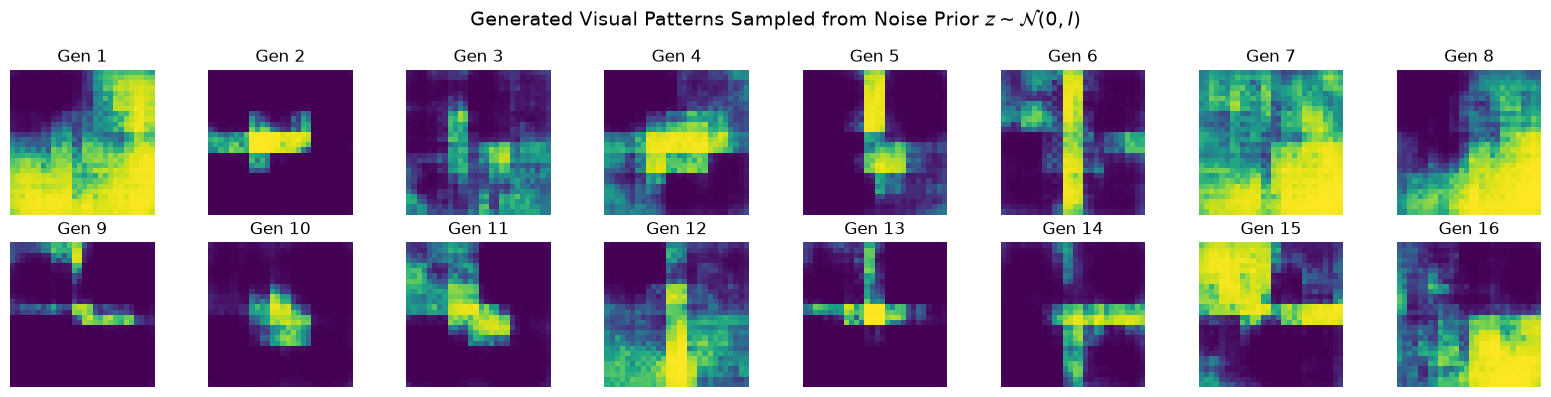

In [4]:
wgan.eval()
with torch.no_grad():
    samples = wgan.sample(num_samples=16, device=device)
    # Rescale [-1, 1] -> [0, 1] for visualization
    samples_vis = (samples + 1.0) / 2.0

fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(samples_vis[i, 0].cpu().numpy(), cmap="viridis", vmin=0, vmax=1)
    ax.axis("off")
    ax.set_title(f"Gen {i+1}")

plt.suptitle("Generated Visual Patterns Sampled from Noise Prior $z \sim \mathcal{N}(0, I)$", fontsize=14)
plt.tight_layout()
plt.show()

---
## Latent Space Traversal (Linear Interpolation $z_1 \to z_2$)
WGAN-GP's smooth 1-Lipschitz critic induces continuous, structured latent spaces without abrupt mode switching.

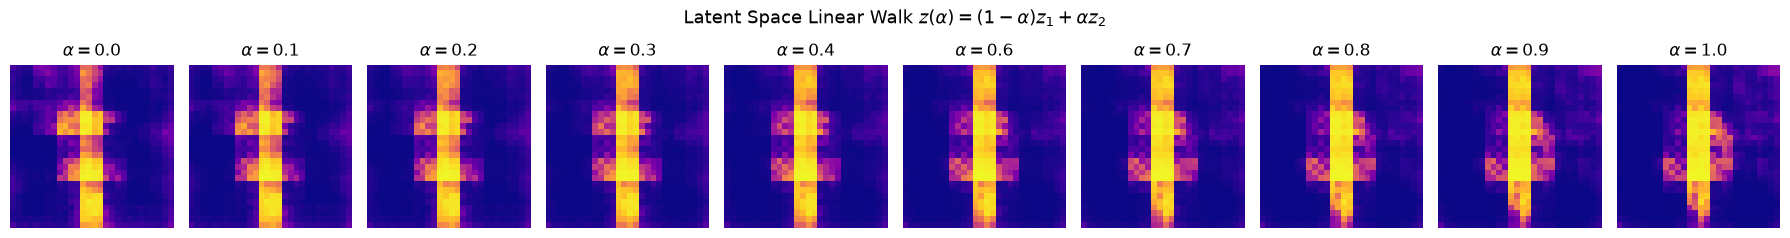

In [6]:
with torch.no_grad():
    z1 = torch.randn(1, 32, device=device)
    z2 = torch.randn(1, 32, device=device)
    alphas = torch.linspace(0.0, 1.0, 10, device=device).unsqueeze(1)
    z_interp = (1.0 - alphas) * z1 + alphas * z2
    interp_imgs = (wgan.generate(z_interp) + 1.0) / 2.0

fig, axes = plt.subplots(1, 10, figsize=(18, 2.5))
for i, ax in enumerate(axes):
    ax.imshow(interp_imgs[i, 0].cpu().numpy(), cmap="plasma", vmin=0, vmax=1)
    ax.axis("off")
    ax.set_title(f"$\\alpha={alphas[i].item():.1f}$")

plt.suptitle("Latent Space Linear Walk $z(\\alpha) = (1 - \\alpha) z_1 + \\alpha z_2$", fontsize=13)
plt.tight_layout()
plt.show()